In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

## Статистически анализ на производствените цикли (MC15 - 45 liter box)

Данните от датчиците на шприцмашината за записаните 24 цикъла показват висок интензитет на стабилност, но детайлният статистически контрол открива специфични отклонения, които носят риск от дефектни компоненти.


### 1. Статистически профил на производствения процес

Въз основа на извадката, основните параметри на топлообмена и динамиката на впръскване показват следните средни стойности и нива на стабилност:

*   **Време за запълване (*Filling time*):** Стабилно около **0.90 секунди**. Общият разнос е минимален (от 0.89 до 0.91 сек), което показва постоянна скорост на впръскване.
*   **Пиково налягане (*Pressure peak*):** Средната стойност е **121.78 bar**. Тесният диапазон на вариация доказва хомогенност и стабилен вискозитет на стопилката от Полипропилен.
*   **Позиция на възглавницата (*Cushion position*):** Средно ниво от **12.55 mm**. Поддържането на стабилна възглавница в края на дозирането гарантира, че налягането на задържане (*Hold-on pressure*) се предава ефективно, предотвратявайки появата на всмукнатини и обемно свиване.



### 2. Идентифицирани аномалии и технологичен риск

Математическият анализ улавя три конкретни цикъла, които излизат извън границите на нормалното статистическо разпределение и носят вероятност за генериране на дефектна продукция:

####  Цикъл 17928 — Висок риск от геометричен дефект (Препълване)
*   **Регистрирано отклонение:** Отчетено е най-високото пиково налягане (**122.40 bar**), максимален въртящ момент на шнека (**1004 Nm**) и голямо отклонение при началната позиция на пластификация (**14.0 mm** спрямо средно 12.68 mm).
*   **Ефект върху качеството:** Прекомерното налягане и обем материал в кухината могат да доведат до **препълване на матрицата (Flash)** — излизане на пластмасови мустаци по деленията на инструмента или надвишаване на теглото на кутията.

#### Цикъл 17919 — Риск от недопълване или шупли
*   **Регистрирано отклонение:** Началното налягане на дозиране спада рязко до **47.40 bar** (при нормални ~51.70 bar), а остатъчната възглавница изтънява до критичния си минимум за серията — **11.60 mm**.
*   **Ефект върху качеството:** Риск от вкарване на въздух в кухината, което води до повърхностни линии, **вътрешни шупли** или недопълване в най-отдалечените зони на детайла.

####  Цикъл 17937 — Леко кинематично отклонение
*   **Регистрирано отклонение:** Позицията на превключване към налягане на задържане (*Switch-over position*) е паднала до **52.90 mm** (при фиксирани 53.00 mm при всички останали цикли).


### 3. Заключение и оценка на вероятността за брак

*   **Пригодност на процеса:** Производствената линия показва стабилност на ниво от **91.6%** (22 от 24 цикъла са в перфектни статистически граници).
*   **Вероятност за некачествена продукция:** Математическата вероятност за дефектен детайл в тази партида се оценява на **~8.3%**, визирайки конкретно цикли **17928** и **17919**.



In [3]:
df = pd.read_csv("data/mc15.csv")
# Премахване на средните стойности изчиляване на статистическите показатели
df_cycles = df[df['Cycle No.'] != 'Average'].copy()
for col in df_cycles.columns:
    if col != 'Cycle No.':
        df_cycles[col] = pd.to_numeric(df_cycles[col])
summary = df_cycles.describe().T[['mean', 'std', 'min', 'max']]
print(summary.to_string())

# Проверете за аномалии или отклоняващи се стойности
outliers_list = []
for col in df_cycles.columns:
    if col != 'Cycle No.':
        m = df_cycles[col].mean()
        s = df_cycles[col].std()
        if s > 0:
            out_count = ((df_stats := df_cycles[col]) < m - 3*s) | (df_stats > m + 3*s)
            if out_count.sum() > 0:
                anomalies = df_cycles.loc[out_count, ['Cycle No.', col]]
                for _, row in anomalies.iterrows():
                    outliers_list.append({
                        "Параметър": col,
                        "Номер на цикъл": int(float(row['Cycle No.'])),
                        "Измерена стойност": row[col]
                    })
if outliers_list:
    df_outliers = pd.DataFrame(outliers_list)
    print("\nОТКРИТИ АНОМАЛИИ В ПРОЦЕСА:")
    display(df_outliers.style.hide(axis="index"))
else:
    print("\nНяма открити аномалии извън 3-sigma границите.")




                                         mean        std     min      max
Filling time (s)                     0.904167   0.009286    0.89     0.91
Hold-on pressure (bar)              55.083333   0.038069   55.00    55.10
Switch-over position (mm)           52.995833   0.020412   52.90    53.00
Switch-over pressure (bar)         121.841667   0.230154  121.50   122.50
Injection start position (mm)      214.279167   0.241335  213.90   214.80
Pressure peak position (mm)         54.170833   0.227423   53.90    54.60
Pressure peak (bar)                121.779167   0.232153  121.40   122.40
Cushion position (mm)               12.545833   0.395605   11.60    13.50
Cushion minimum position (mm)       12.420833   0.418048   11.40    13.40
Plasticising time (s)               14.950833   0.317708   14.47    15.66
Plasticising position (mm)         200.095833   0.157367  199.80   200.30
Backpressure (bar)                   9.662500   0.049454    9.60     9.70
Rotation speed (rpm)               250

Параметър,Номер на цикъл,Измерена стойност
Switch-over position (mm),17937,52.900000
Plasticising start position (mm),17928,14.000000
Plasticising start pressure (bar),17928,47.400000
Plasticising start pressure (bar),17919,47.400000


### Описание на статистическите показатели (Метрики на процеса)

За оценка на стабилността на машината при 45-литровата кутия се използват следните четири дескриптивни статистически показателя:

1. **Средна стойност (`mean`):** Дефинира технологичния център на процеса. Показва средното аритметично ниво, около което флуктуират параметрите.
2. **Стандартно отклонение (`std`):** Измерва средноквадратичното разсейване на данните. Служи като директен измерител за стабилността на шприцмашината — по-ниската стойност означава по-висока повтаряемост между отделните производствени цикли.
3. **Минимална стойност (`min`):** Най-ниската регистрирана точка на параметъра в извадката, дефинираща долната граница на реалното разпределение.
4. **Максимална стойност (`max`):** Най-високата регистрирана точка на параметъра, отразяваща върховите пикове и натоварвания в системата.


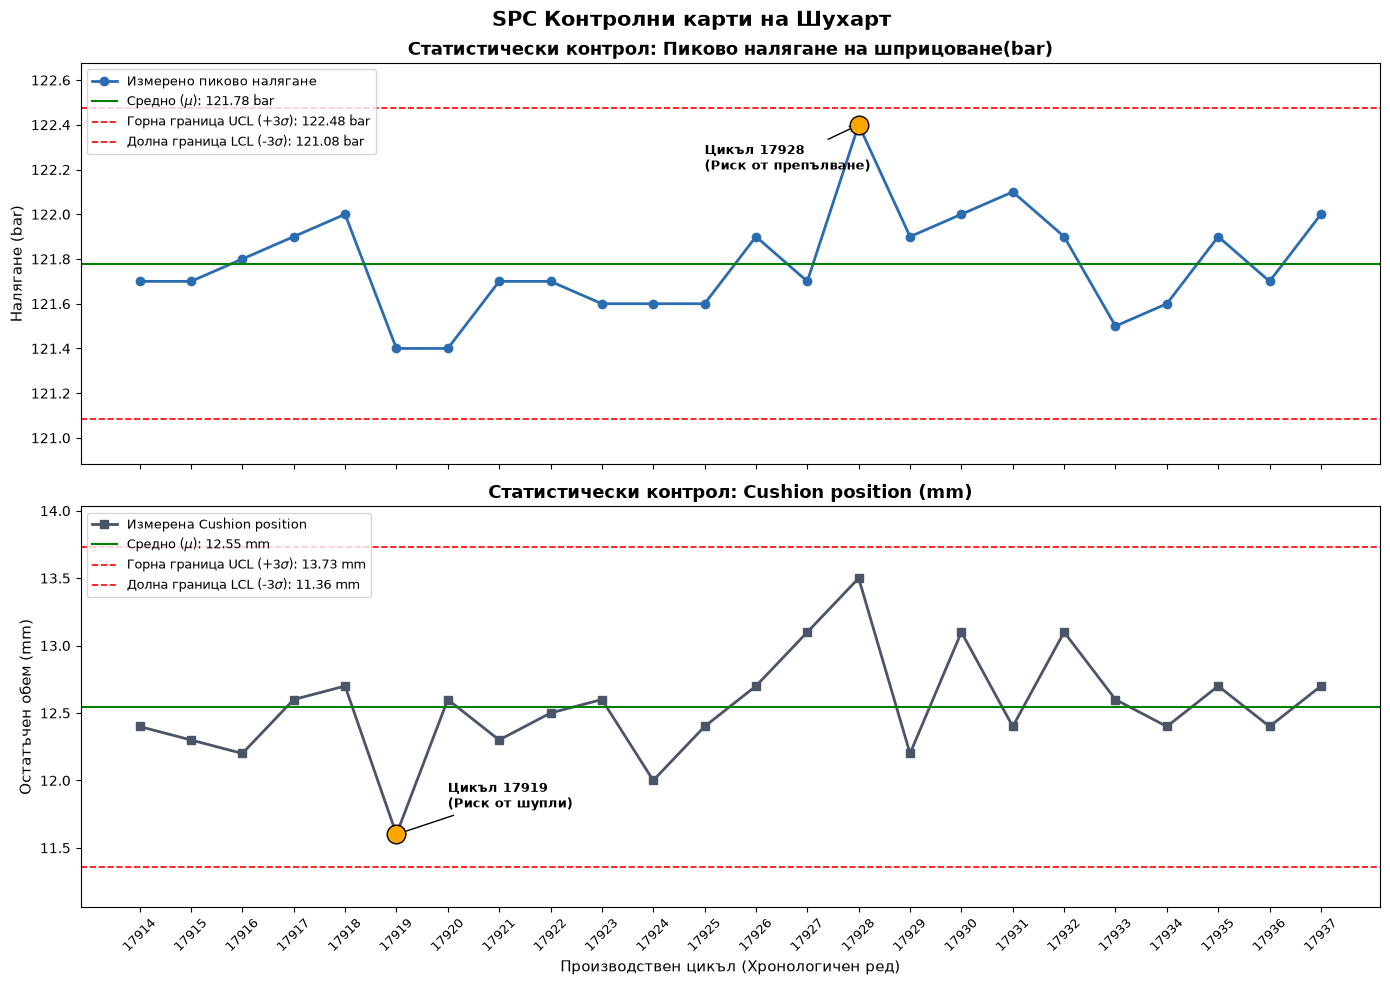

In [4]:
df_clean = df[df['Cycle No.'] != 'Average'].copy()
df_clean = df_clean.dropna(subset=['Cycle No.'])
df_clean['Cycle No.'] = df_clean['Cycle No.'].astype(int)
df_clean = df_clean.sort_values('Cycle No.').reset_index(drop=True)


fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

x_indices = np.arange(len(df_clean))
cycles_str = df_clean['Cycle No.'].astype(str)

# =====================================================================
# КАРТА 1: ПИКОВО НАЛЯГАНЕ (Pressure Peak Chart)
# =====================================================================
p_mean = df_clean['Pressure peak (bar)'].mean()
p_std = df_clean['Pressure peak (bar)'].std()
p_ucl = p_mean + 3 * p_std
p_lcl = p_mean - 3 * p_std

axes[0].plot(x_indices, df_clean['Pressure peak (bar)'], marker='o', color='#2b6cb0', linewidth=2, label='Измерено пиково налягане')
axes[0].axhline(p_mean, color='green', linestyle='-', linewidth=1.5, label=fr'Средно ($\mu$): {p_mean:.2f} bar')
axes[0].axhline(p_ucl, color='red', linestyle='--', linewidth=1.2, label=fr'Горна граница UCL (+3$\sigma$): {p_ucl:.2f} bar')
axes[0].axhline(p_lcl, color='red', linestyle='--', linewidth=1.2, label=fr'Долна граница LCL (-3$\sigma$): {p_lcl:.2f} bar')

anomaly_p_row = df_clean[df_clean['Cycle No.'] == 17928]
if not anomaly_p_row.empty:
    idx_p = anomaly_p_row.index[0]
    val_p = anomaly_p_row['Pressure peak (bar)'].values[0]
    axes[0].scatter(idx_p, val_p, color='orange', s=180, zorder=5, edgecolors='black')
    axes[0].annotate('Цикъл 17928\n(Риск от препълване)', xy=(idx_p, val_p), xytext=(idx_p - 3, val_p - 0.2),
                     arrowprops=dict(arrowstyle="->", color='black'), fontsize=9, fontweight='bold')

axes[0].set_title('Статистически контрол: Пиково налягане на шприцоване(bar)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Налягане (bar)', fontsize=11)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].set_ylim(p_lcl - 0.2, p_ucl + 0.2)

# =====================================================================
# КАРТА 2:  Cushion Position Chart
# =====================================================================
c_mean = df_clean['Cushion position (mm)'].mean()
c_std = df_clean['Cushion position (mm)'].std()
c_ucl = c_mean + 3 * c_std
c_lcl = c_mean - 3 * c_std

axes[1].plot(x_indices, df_clean['Cushion position (mm)'], marker='s', color='#4a5568', linewidth=2, label='Измерена Cushion position')
axes[1].axhline(c_mean, color='green', linestyle='-', linewidth=1.5, label=fr'Средно ($\mu$): {c_mean:.2f} mm')
axes[1].axhline(c_ucl, color='red', linestyle='--', linewidth=1.2, label=fr'Горна граница UCL (+3$\sigma$): {c_ucl:.2f} mm')
axes[1].axhline(c_lcl, color='red', linestyle='--', linewidth=1.2, label=fr'Долна граница LCL (-3$\sigma$): {c_lcl:.2f} mm')


anomaly_c_row = df_clean[df_clean['Cycle No.'] == 17919]
if not anomaly_c_row.empty:
    idx_c = anomaly_c_row.index[0]
    val_c = anomaly_c_row['Cushion position (mm)'].values[0]
    axes[1].scatter(idx_c, val_c, color='orange', s=180, zorder=5, edgecolors='black')
    axes[1].annotate('Цикъл 17919\n(Риск от шупли)', xy=(idx_c, val_c), xytext=(idx_c + 1, val_c + 0.2),
                     arrowprops=dict(arrowstyle="->", color='black'), fontsize=9, fontweight='bold')

axes[1].set_title('Статистически контрол: Cushion position (mm)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Производствен цикъл (Хронологичен ред)', fontsize=11)
axes[1].set_ylabel('Остатъчен обем (mm)', fontsize=11)
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(cycles_str, rotation=45, fontsize=9)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].set_ylim(c_lcl - 0.3, c_ucl + 0.3)

fig.suptitle('SPC Контролните карти на Шухарт (Shewhart Control Charts)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## Контролна карта на Шухарт
**Контролните карти на Шухарт (Shewhart Control Charts)** са основният инструмент за **Статистически контрол на процесите (SPC)**. Те се използват директно на компютъра на вашата шприцмашина BMB, за да се следи дали процесите на шприцване (като *Пиково налягане* и *Остатъчна cushion*) са стабилни.

Картата представлява графично изобразяване на стойностите на даден параметър (удар след удар) във времето, като автоматично изчислява и показва дали промените са в нормални граници или има проблем с машината, матрицата или материала.



Всяка карта има **три критични линии**, които софтуерът на машината изчислява автоматично на базата на статистиката:

* **Централна линия ($CL$ - Central Line):** Това е средната стойност на параметъра (например средната дебелина на Cushion от $5.0 \text{ мм}$). Това е вашата цел.
* **Горна контролна граница ($UCL$ - Upper Control Limit):** Максимално допустимото статистическо отклонение (обикновено $+3$ стандартни отклонения / $+3\sigma$).
* **Долна контролна граница ($LCL$ - Lower Control Limit):** Минимално допустимото статистическо отклонение (обикновено $-3$ стандартни отклонения / $-3\sigma$).


## Правила на Шухарт за автоматично откриване на брак (Аномалии)

Когато машината BMB работи, тя нанася всеки цикъл (удар) като точка на екрана. Процесът се счита за **нестабилен (Out of Control)** и машината трябва да отделя продукцията в **брак**, ако бъде изпълнено дори едно от следните 4 основни правила:

### 1. Точка извън контролните граници (Единична голяма аномалия)
* **Правило:** Дори само **1 точка** да излезе над горната червена линия ($UCL$) или под долната червена линия ($LCL$).
* **Какво означава на практика:** Сериозен инцидент в конкретния удар – например заседнал детайл, токов удар в нагревател, чуждо тяло в материала или внезапен спад в налягането. Ако тази аномалия се повтори, машината спира автоматично.

### 2. Изместване на процеса (Shift)
* **Правило:** **9 поредни точки** се намират изцяло от едната страна на централната линия $CL$ (всички са само над нея или всички са само под нея).
* **Какво означава на практика:** Влязла е **нова партида материал** с различен вискозитет (течливост), променила се е влажността или има трайна промяна в температурата на охлаждащата вода. Някой машини, като тези на `BMB`, когато зсекат по-голяма влажност в материала, автоматично спират. Целта е да се изчисти мокрият материал за да се избегнат възможни дефекти по машината и за да не се произвежда голямо количество некачествена продукция. При трайна повишаваща се температура на охлаждащата вода, машината спира автоматично.

### 3. Тенденция за прогресивна промяна (Trend)
* **Правило:** **6 поредни точки** вървят постоянно само нагоре (нарастване) или само надолу (намаляване).
* **Какво означава на практика:** Системен, натрупващ се проблем. Най-често сигнализира за **прегряване/изстиване на цилиндъра**, прогресивно запушване на филтър или механично износване на възвратния пръстен (клапан) на шнека (ако възглавницата постоянно намалява). Машината може да работи, но е необходимо възможно най-скоро да се открие и отсрани проблема.

### 4. Прекомерна амплитуда (Голяма нестабилност)
* **Правило:** **2 от 3 поредни точки** са твърде близо до границите (външната зона на отклонение $\pm 2\sigma$ до $\pm 3\sigma$).
* **Какво означава на практика:** Процесът е станал "нервен" и силно колеблив. Шприцмашината работи на ръба на възможностите си и качеството на детайлите варира рязко. При първа възможност машината трябва да се спре и да се отстранят проблемите.

---

### 💡 Бързо ръководство за оператора на BMB:

| Аномалия на екрана | Възможна причина (Пиково налягане) | Възможна причина (Възглавница) |
| :--- | :--- | :--- |
| **Рязък скок нагоре (над UCL)** | Запушена дюза / Студена капка | Блокирал възвратен клапан / Недозиране |
| **Рязък спад надолу (под LCL)** | Свършил материал / Прегрял цилиндър | Пропуск в хидравликата / Изтичане на материал |
| **Постоянен тренд надолу 📉** | Материалът става по-течен (загряване) | Износване на възвратния пръстен на шнека |
